!!! info Les structures linéaires
    
# Les listes chainées  
    
### Définition wikipédia    
    
Une liste chaînée ou liste liée (en anglais linked list) désigne en informatique une structure de données représentant une **collection ordonnée** et de **taille arbitraire d'éléments de même type**, dont la représentation en mémoire de l'ordinateur est une **succession de cellules faites d'un contenu et d'un pointeur** vers une autre cellule. De façon imagée, l'ensemble des cellules ressemble à une chaîne dont les maillons seraient les cellules.

L'accès aux éléments d'une liste se fait de manière **séquentielle** : **chaque élément permet l'accès au suivant** (contrairement au tableau dans lequel l'accès se fait de manière directe, par adressage de chaque cellule dudit tableau).

### Principe   
    
Le principe de la liste chaînée est que chaque élément possède, en plus de la donnée, un pointeur vers un élément qui lui est contigu dans la liste. L'usage d'une liste est souvent préconisé pour des raisons de rapidité de traitement, lorsque l'ordre des éléments est important et que les insertions et les suppressions d'éléments quelconques sont plus fréquentes que les accès.

En effet, les insertions en début ou fin de liste et les suppressions se font en temps constant car elles ne demandent au maximum que deux écritures. En revanche, l'accès à un élément quelconque nécessite le parcours de la liste depuis le début jusqu'à l'index de l'élément choisi.    
    
Il ne faut pas confondre cette structure de liste avec les listes Python qui sont en fait une structure bien plus riche, que l'on pourrait qualifier de tableau dynamique.   
    
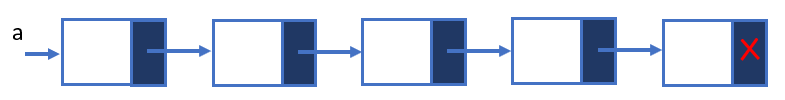
    
### Interface  
    
Voici quelques opérations possibles sur les listes chaînées :
    
- **Ajouter/retirer** un élément au début, à la fin, à l'intérieur :  
    
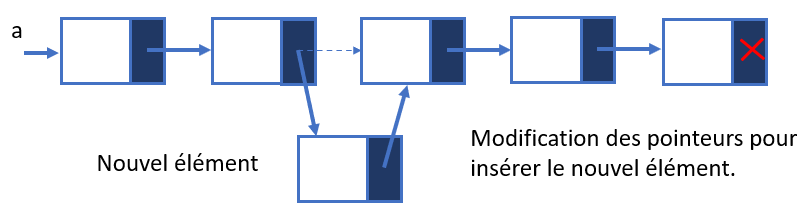
    
- **Concaténer** deux listes :       

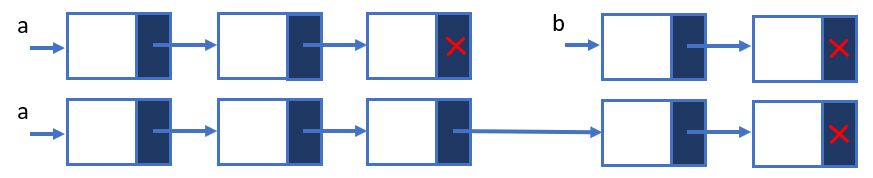   
    
- **Couper** une liste en deux :   
    
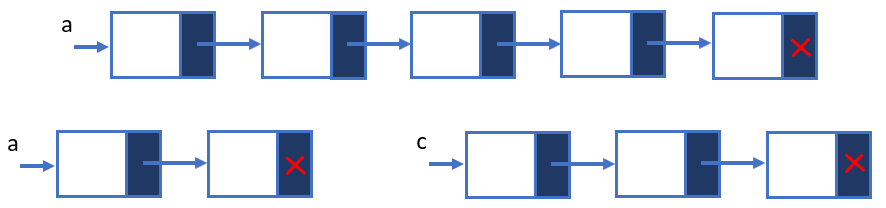
    
- **Accéder** au nième élément ;   
- **Rechercher** la présence d'un élément ;     
- ...    
!!!    

<div class = "alert alert-block alert-info">   
    
    
# Implémentation d’une liste chainée  
    
    
## Classe Cellule

La classe Cellule permet d’instancier des objets représentant une cellule d’une liste chainée. Le constructeur de cette classe initialise deux attributs d’instance : 
    
    
- **`value`** : La valeur de la cellule.
- **`next_cell`** : Cellule suivante. C’est une instance de la classe Cellule.  
    
    
La classe contient en outre deux autres attributs utilisés uniquement pour faciliter le debuggage. Vous n'êtes pas obligé de comprendre précisément leur implémentation. Un attribut de classe **`_compt`** qui permet de compter les cellules est incrémenté à chaque nouvelle instanciation. Cela permet de définir un attribut d’instance privé **`_idCell`** qui permet de numéroter individuellement chaque cellule pour faciliter le debug.  
    
    
D’autres méthodes sont implémentés dans cette classe :  
    
- **`set_value(value)`** : modifie la valeur de la cellule.
- **`set_suivant(cell)`** : Modifie le pointeur vers la cellule suivante. **`cell`** est une instance de **`Cellule`**.
- **`__repr__()`** : fourni une chaine de caractère représentant l’identifiant et le contenu de la cellule : valeur, pointeur vers cellule suivante. 
 
Exemples d’utilisation de cette classe :

```python
>>> a = Cellule(12)
>>> b = Cellule(20)
>>> a
C1 : (12, None)
>>> b
C2 : (20, None)
>>> a.set_suivant(b)
>>> a
C1 : (12, C2)
>>> a.value
12
>>> a.next_c
C2 : (20, None)
```
    
</div>    

In [ ]:
from tutor import tutor

In [ ]:
class Cellule:
    #attribut de classe pour numéroter les cellules au fur et a mesure de leur création
    #pour débug -> a supprimer en version définitive
    _compt = 0
    
    def __init__(self, value, next_cell=None):
        """
        Classe pour modéliser une cellule de la liste chainée
        2 attributs publics :
            value : valeur de la cellule
            nextC : pointeur vers la cellule suivante (autre instance de Cellule)
        """
        # compte une cellule de plus
        Cellule._compt += 1
        # sauvegarde le numéro de la celule
        self._id_cell = Cellule._compt # pour debug
        #attributs publics
        self.value = value
        assert isinstance(next_cell, (Cellule, type(None)))
        self.next_cell = next_cell
    
    def set_value(self, value):
        """modifie la valeur de la cellule
        """
        self.value = value    

    def set_suivant(self, cell):
        """Modifie le pointeur vers la cellule suivante. cell est une instance de Cellule
        """
        assert isinstance(cell, (Cellule, type(None)))
        self.next_cell = cell
        
    def _get_id(self):
        # pour debug uniquement
        # renvoi le numéro de la cellule
        return 'C' + str(self._id_cell)

    def __repr__(self):
        if self.next_cell != None:
            str_next = self.next_cell._get_id()
        else:
            str_next = "None"
            
        return self._get_id() + ' : (' + str(self.value) + ', ' + str_next + ')'



<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer

Testez cette classe ci-dessous, en utilisant toutes ses méthodes. 
</div>

<div class = "alert alert-block alert-info"> 
    
## Implémention d'une classe Liste

La classe Liste permet d’instancier des objets représentant une liste chainée. Le constructeur de cette classe initialise deux attributs d’instances :  
- **`cell_debut`** : créé une cellule de début de liste. Elle sera initialisée à la valeur passée en argument.  
- **`taille`** : le nombre de cellule chainée. Remis a jour a chaque modification. 
    
Méthode implémentée :   
- **`__repr__()`** : Affiche le contenu de chaque cellule (le str renvoyé par la méthode __repr__ de la cellule). C’est une version de debug : c’est pour cela qu’on indiquera les identifiants de la cellule et de sa suivante.
    
***Limitation importante :*** Pour simplifier les écritures, le but ici étant avant tout pédagogique, la notion de liste vide n'est pas abordée ici. On ne peut pas créer une liste vide, et on ne peut pas supprimer la dernière valeur d'une liste. C'est un choix pédagogique.   
    
### Les méthodes de base : début de liste
Vous implémenterez les méthodes suivantes :  
- **`__init__(valeur)`** : Constructeur de la classe.
- **`ajoute_d(valeur)`** : Ajoute une nouvelle cellule contenant valeur au début de la liste.
- **`retire_d()`** : Supprime la première cellule de la liste et la renvoie.
- **`__len__()`** : Renvoie le nombre de cellule dans la liste chainée. Complexité O(1) : **opération a coût constant**.
  

 
Exemples d’utilisation des méthodes décrites ci-dessus :

```python
>>> l1 = Liste(22)
>>> l1
(C1 : (22, None))
>>> len(l1)
1
>>> l1.ajoute_d(18)
>>> l1.ajoute_d(12)
>>> l1.ajoute_d(9)
>>> l1
(C4 : (9, C3), C3 : (12, C2), C2 : (18, C1), C1 : (22, None))
>>> len(l1)
4
>>> l1.retire_d()
9    
>>> l1
(C3 : (12, C2), C2 : (18, C1), C1 : (22, None))    
```
   
</div>    

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer
   
Implémentez ces méthodes dans la classe suivante :
    
```python
class Liste:
    """Classe pour modéliser une liste chainée.
    
    attribut publique
    -----------------
    cell_debut : Instance de la classe Cellule
        Pointe la cellule de départ de la liste. 
        Ne peut pas être None : la liste comporte toujours au moins un élément.
    """    
    def __init__(self, value):
        """Constructeur de la classe
        
        parametre
        ---------
        value : tous types
            Première valeur de la liste
        """
        ...
    
    ### DEBUT DE LISTE
    
    def ajoute_d(self, value):
        """Ajoute une valeur au début de la liste."""
        ...
    
    def retire_d(self):
        """Retire en renvoie la première valeur de la liste."""
        ...
        
    def __len__(self):
        """Renvoie le nombre d'élément de la liste."""
        ...
   
    #### FIN DE LISTE
    
    def dernier(self):
        """Renvoi un lien symbolique vers la dernière cellule de la liste. Ne supprime rien.
        """
        ...  
    
    def ajoute_f(self, value):
        """Ajoute une valeur à la fin de la liste."""
        ...
        
    def retire_f(self):
        """Retire et renvoie la derniere valeur. idem pop."""
        ...
    
    def copie(self):
        """Renvoie une copie indépendante."""
        ...
    
    def concatener(self, lst):
        """Ajoute les valeurs de lst a la fin de la liste. Cette liste reste indépendante de lst."""
        ...
        
    #### MILEU DE LISTE        
        
    def get(self, i):
        """Renvoie la valeur de l'élément d'indice i. La liste n'est pas modifiée."""
        ...

    def inserer(self, i, value):
        """Ajoute une valeur à l'indice i, les éléments déjà présents sont décalés."""
        ...
            
    def couper(self, j):
        """Coupe la liste juste avant l'indice j. 
        Renvoie une nouvelle liste constituée des éléments d'indice j et plus."""
        if j == 0 or j > self.taille - 1:
            # aucun des deux morceaux ne doit être vide
            raise ValueError('La liste ne peut pas être vide')
            
        ...
    
    def __repr__(self):
        c = self.cell_debut
        txt = '(' + repr(c)
        while c.next_cell is not None:
            c = c.next_cell
            txt += ', ' + repr(c)
        txt += ')'
        return txt
        
    
```    
    
Testez-les !
</div>

In [ ]:
class Liste:
    """Classe pour modéliser une liste chainée.
    
    attribut publique
    -----------------
    cell_debut : Instance de la classe Cellule
        Pointe la cellule de départ de la liste. Ne peut pas être None : la liste comporte toujours au moins un élément.
    """    
    def __init__(self, value):
        """Constructeur de la classe
        
        parametre
        ---------
        value : tous types
            Première valeur de la liste
        """
        ...
    
    ### DEBUT DE LISTE
    
    def ajoute_d(self, value):
        """Ajoute une valeur au début de la liste."""
        ...
    
    def retire_d(self):
        """Retire en renvoie la première valeur de la liste."""
        ...
        
    def __len__(self):
        """Renvoie le nombre d'élément de la liste."""
        ...
   
    #### FIN DE LISTE
    
    def dernier(self):
        """Renvoi un lien symbolique vers la dernière cellule de la liste. Ne supprime rien.
        """
        ...  
    
    def ajoute_f(self, value):
        """Ajoute une valeur à la fin de la liste."""
        ...
        
    def retire_f(self):
        """Retire et renvoie la derniere valeur. idem pop."""
        ...
    
    def copie(self):
        """Renvoie une copie indépendante."""
        ...
    
    def concatener(self, lst):
        """Ajoute les valeurs de lst a la fin de la liste. Cette liste reste indépendante de lst."""
        ...
        
    #### MILEU DE LISTE        
        
    def get(self, i):
        """Renvoie la valeur de l'élément d'indice i. La liste n'est pas modifiée."""
        ...

    def inserer(self, i, value):
        """Ajoute une valeur à l'indice i, les éléments déjà présents sont décalés."""
        ...
            
    def couper(self, j):
        """Coupe la liste juste avant l'indice j. Renvoie une nouvelle liste constituée des éléments d'indice j et plus."""
        if j == 0 or j > self.taille - 1:
            # aucun des deux morceaux ne doit être vide
            raise ValueError('La liste ne peut pas être vide')
            
        ...
    
    def __repr__(self):
        c = self.cell_debut
        txt = '(' + repr(c)
        while c.next_cell is not None:
            c = c.next_cell
            txt += ', ' + repr(c)
        txt += ')'
        return txt
        


<div class = "alert alert-block alert-info"> 
   
### Les méthodes pour la fin de la liste  
    
Vous implémenterez les méthodes suivantes :   
- **`dernier()`** : Renvoie la dernière cellule sans la supprimer.
- **`ajoute_f(valeur)`** : Ajoute une nouvelle cellule contenant valeur à la fin de la liste.
- **`copie()`** : renvoie une copie de la liste.
- **`concatener(L)`** : Ajoute une copie de la liste **`L`** à la fin de la liste.
- **`retire_f()`** : Supprime la dernière cellule et renvoie la valeur : fonctionnement idem `pop`.
 
Exemples d’utilisation des méthodes décrites ci-dessus :
 
```python
>>> l1 = Liste(22)
>>> l1.ajoute_f(45)
>>> l1.ajoute_f(53)
>>> l1.ajoute_f(66)
>>> l1
(C1 : (22, C2), C2 : (45, C3), C3 : (53, C4), C4 : (66, None))
>>> l1.retire_f()
66
>>> l1.retire_f()
53
>>> l1
(C1 : (22, C2), C2 : (45, C3))
>>> l2 = Liste(1)
>>> l2.ajoute_f(2)
>>> l2.ajoute_f(3)
>>> l2
(C5 : (1, C6), C6 : (2, C7), C7 : (3, None))
>>> l1.concatener(l2)
>>> l1
(C1 : (22, C2), C2 : (45, C3), C3 : (53, C4), C4 : (66, C8), C8 : (1, C9), C9 : (2, C10), C10 : (3, None))
>>> l2.copie()
(C11 : (1, C12), C12 : (2, C13), C13 : (3, None))
```
    
</div>    

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer
   
Implémentez ces méthodes.  
Testez-les !
</div>

<div class = "alert alert-block alert-info"> 
   
### Les méthodes du milieu de la liste
    
Vous implémenterez les méthodes suivantes :   
- **`get(i)`** : Renvoie la valeur d’index i sans la supprimer.
- **`inserer(valeur, i)`** : Ajoute une nouvelle cellule contenant valeur à l’index i de la liste.
- **`couper(j)`** : Coupe la liste juste avant l’index j. La deuxième partie de la liste est retournée

 
Exemples d’utilisation des méthodes décrites ci-dessus :
 
```python
>>> l1 = Liste(10)
>>> l1.ajoute_f(20)
>>> l1.ajoute_f(30)
>>> l1.ajoute_f(40)
>>> l1
(C1 : (10, C2), C2 : (20, C3), C3 : (30, C4), C4 : (40, None))
>>> l1.inserer(100, 2)
>>> l1
(C1 : (10, C2), C2 : (20, C5), C5 : (100, C3), C3 : (30, C4), C4 : (40, None))
>>> l1.get(0)
10
>>> l1.get(2)
100
>>> l2 = l1.couper(3)
>>> l1
(C1 : (10, C2), C2 : (20, C5), C5 : (100, None))
>>> l2
(C3 : (30, C4), C4 : (40, None))
```
    
</div>    

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer
   
Implémentez ces méthodes.  
Testez-les !
</div>

In [ ]:
l1 = Liste(10)
for u in range(20, 81, 10):
    l1.ajoute_f(u)
print(l1, len(l1))
print(l1.get(0))
print(l1.get(1))
print(l1.get(7))
print(l1.get(8)) # déclenche un exception

In [ ]:
l1 = Liste(10)
l1.ajoute_f(20)
l1.ajoute_f(30)
print(l1)
l1.inserer(1, 15)
l1.inserer(3, 25)
l1.inserer(0, 5)
print(l1)
print(len(l1))

In [ ]:
l1 = Liste(10)
l1.ajoute_f(20)
l1.ajoute_f(30)
l1.ajoute_f(40)
print(l1)
l2 = l1.couper(2) # tester avec les valeurs 1, 2, 3. Doit planter pour 0 et 4
print(l1, len(l1))
print(l2, len(l2))

!!! info Comparaison entre listes et tableaux

Le stockage en mémoire des structures linéaires peut se faire de plusieurs manières.


## Les tableaux   

Un tableau est une suite contiguë de cases mémoires (les adresses des cases mémoire se suivent) :

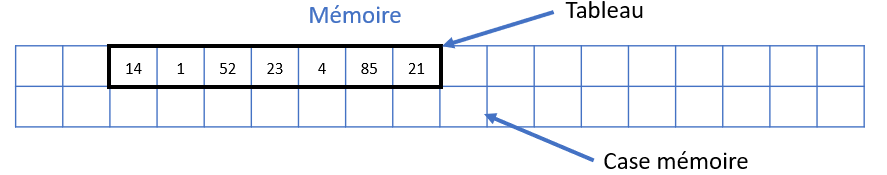

**La taille d'un tableau est fixe** : une fois que l'on a défini le nombre d'éléments que le tableau peut accueillir, il n'est pas possible de modifier sa taille. Si l'on veut insérer une donnée, on doit créer un nouveau tableau plus grand et déplacer les éléments du premier tableau vers le second tout en ajoutant la donnée au bon endroit ! Il s'agit par exemple des **`array`** en langage **`C`**.

## Les tableaux dynamiques

Dans certains langages de programmation, on trouve une version "*évoluée*" des tableaux : les tableaux dynamiques. Ils ont une taille plus importante que les données qu ’ils contiennent. Cela permet de pouvoir ajouter des données sans réallouer trop fréquemment la mémoire.

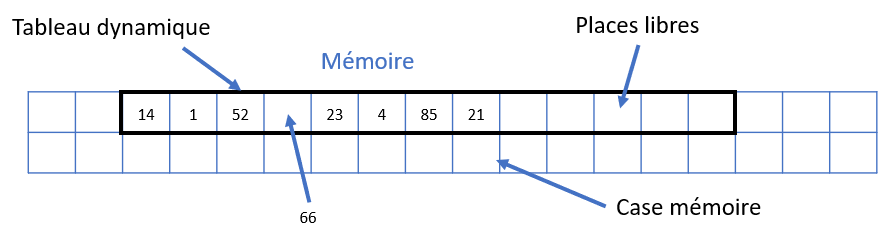

Les **listes Python** sont des **tableaux dynamiques**. Attention de ne pas confondre avec le type abstrait liste défini ci-dessus, ce sont de "faux amis".

## Complexité des opérations courantes

L'efficacité des différents algorithme dépend énormément de l'organisation en mémoire. Voici les cas courants : 

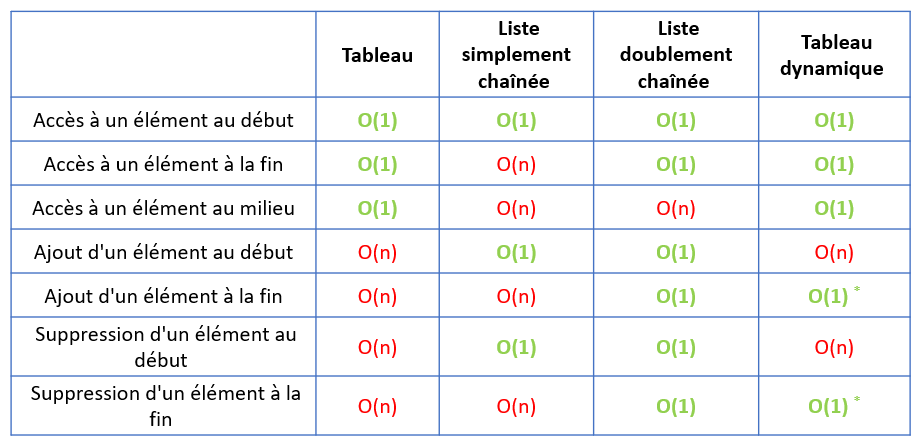

* Complexité moyenne. Un ajout ou une suppression prise individuellement peut être de complexité O(n).


!!!

<div class = "alert alert-block alert-info"> 
    
## Implémentation d’une classe Pile en utilisant les listes chainées.

***Objectif :*** Implémenter une pile en utilisant la classe **`Cellule`**.      
    
Définissez une classe **`Pile`**, qui permette d’instancier des objets représentant des piles. Le constructeur de cette classe initialisera deux attributs d’instance :   
- **`_cell_dessus_pile`** : `Cellule` ou `None`. La cellule du dessus de la pile ou `None` si la pile est vide. 
- **`_taille`** : `int`. La taille de la pile.   
 
    
D’autres méthodes seront définies :   
- **`valeur()`** renvoie la valeur au sommet de la pile sans modifier la pile. Une exception est levée si la pile est vide.
- **`depile()`** dépile le dernier élément saisi, renvoie la valeur dépilée. Une exception est levée si la pile est vide.
- **`empile(v)`** empile la valeur v ;
- **`est_vide()`** renvoi True si la pile est vide, False sinon ;
- **`__len__()`** renvoi le nombre d’élément de la pile.
    
    
Exemples d’utilisation de cette classe :
   
```python
>>> p = Pile()
>>> p
|∅ ←
>>> p.est_vide()
True
>>> p.empile(2)
>>> p.empile(4)
>>> p.empile(6)
>>> p.est_vide()
False
>>> p
|... 6 ⇆
>>> len(p)
3
>>> p.valeur()
6
>> p.depile()
6
>>> p.depile()
4
>>> p
|... 2 ⇆
>> p.depile()
2
>>> p.est_vide()
True
```
    
</div>  
   
  
    
</div>  

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer
   
Implémentez cette classe et toutes ses méthodes.  
    
```python    
class Pile:
    def __init__(self):
        """Initialisation d'une pile vide.
        """
        self._cell_dessus_pile = ...
        self._taille = ...

    def valeur(self):
        """Renvoie la valeur au sommet de la pile.
        """
        ...

    def depile(self):
        """Dépile le dernier élément saisi,
        Renvoie la valeur dépilée.
        """
        ...
    
    def empile(self, v):
        """Empile la valeur v
        """
        ...
    
    def est_vide(self):
        """Renvoie True si la pile est vide, False sinon.
        """
        ...
    
    def __len__(self):
        """Renvoie le nombre d'élément dans la pile
        """
        ...    
```    
    
Testez-là !
</div>

In [ ]:
class Pile:
    def __init__(self):
        """Initialisation d'une pile vide.
        """
        self._cell_dessus_pile = ...
        self._taille = ...

    def valeur(self):
        """Renvoie la valeur au sommet de la pile.
        """
        ...

    def depile(self):
        """Dépile le dernier élément saisi,
        Renvoie la valeur dépilée.
        """
        ...
    
    def empile(self, v):
        """Empile la valeur v
        """
        ...
    
    def est_vide(self):
        """Renvoie True si la pile est vide, False sinon.
        """
        ...
    
    def __len__(self):
        """Renvoie le nombre d'élément dans la pile
        """
        ...  
    
    def __repr__(self):
        """renvoi une représentation str de toute la pile
        """
        txt = ""
        c = self._cell_dessus_pile
        while c is not None:
            txt += f"|{c.value}|\n"
            c = c.next_cell
        txt += "|#|"
        return txt  
    
    def __str__(self): 
        """renvoi une représentation str du sommet de la pile.
        """
        if self.est_vide():
            return '|∅ ←'
        return f"|... {self.valeur()} ⇆"         


In [ ]:
# testez la classe Pile ici
p = Pile()
print(p)
print(p.est_vide())
print(len(p))
p.empile(1)
p.empile(2)
p.empile(3)
print(p.est_vide())
print(len(p))
print(p)
print(p.valeur())
print(p)

!!! info Les listes doublement chainées

Si l'on souhaite disposer d'opérations rapides au début et à la fin de la liste, on peut utiliser une structure de liste doublement chaînée. Chaque cellule contiendra maintenant un pointeur vers la cellule précédente. On conserve en permanence dans la structure un pointeur vers la première et vers la dernière cellule. Schématiquement :

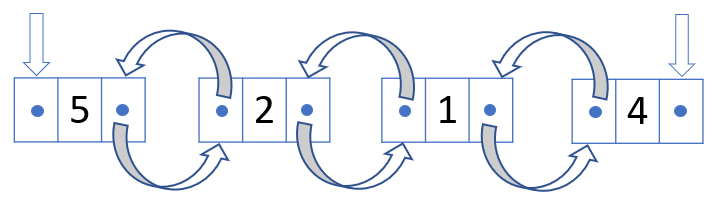

Cela est obtenu au prix de plusieurs inconvénients :    
- Encombrement mémoire plus grand (pour stocker le second pointeur de chaque cellule) ;   
- Surcoût en nombre d'opérations pour gérer les pointeurs supplémentaires lors d'un ajout ou d'une suppression.






!!!

<div class = "alert alert-block alert-info"> 
    
## Implémentation d’une classe File en python avec des listes doublement chainées.

Définissez une classe **`File`**, qui permette d’instancier des objets représentant des structures **FIFO**. Le constructeur de cette classe initialisera deux attributs d’instance :   
- **`_cell_entree`** : `CelluleDoubleChainage` ou `None`. La cellule d'entreé de la file ou None si la file est vide.     
- **`_cell_sortie`** : `CelluleDoubleChainage` ou `None`. La cellule de sortie de la file ou None si la file est vide. 
- **`_taille`** : `int`. La taille de la file. 
    
D’autres méthodes seront définies :
- **`valeur()`** renvoi la plus ancienne valeur de la file sans modifier la file. Une exception est levée si la pile est vide.
- **`defile()`** défile le premier élément saisi, renvoie la valeur défilée. Une exception est levée si la pile est vide.
- **`enfile(v)`** emfile la valeur v ;
- **`est_vide()`** renvoi True si la file est vide, False sinon ;
- **`__len__()`** renvoi le nombre d’élément de la file.   
    
    
Exemples d’utilisation de cette classe :

```python
>>> f = File()
>>> f
⭢ ∅
>>> f.est_vide()
True
>>> f.enfile(2)
>>> f.enfile(4)
>>> f.enfile(6)
>>> f.est_vide()
False
>>> f
⭢ 6 ... 2 ⭢
>>> len(f)
3
>>> f.valeur()
2
>> f.defile()
2
>>> f.defile()
4
>>> f
⭢ 6 ⭢
>> f.defile()
6
>>> f.est_vide()
True
```   
    
Cette classe devra s'appuyer sur une nouvelle classe **`CelluleDoubleChainage`** qui permet un double chainage : vers la cellule suivante et vers la cellule précédente. Cette classe est fournie :
    
```python
class CelluleDoubleChainage:
    def __init__(self, value):
        self.value = value
        self.cell_avant = None
        self.cell_apres = None
        
    def set_suivant(self, cell):
        if not isinstance(cell, (CelluleDoubleChainage, type(None))):
            raise ValueError('Type cell incorrecte.')  
        self.cell_apres = cell
        
    def set_precedent(self, cell):
        if not isinstance(cell, (CelluleDoubleChainage, type(None))):
            raise ValueError('Type cell incorrecte.')  
        self.cell_avant = cell
```    
    
Avec ces cellules, nous allons pouvoir garder un lien avec la première est la dernière cellule. Cela permet de réaliser les opérations d'enfilage et de défilage avec une complexité constante **O(1)**. 
    
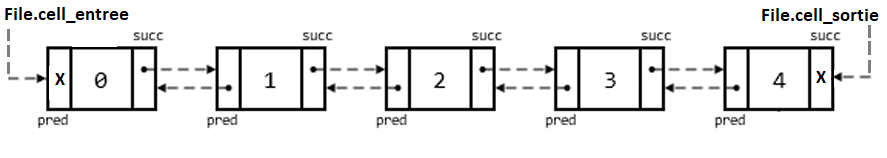    
    
#### Exemple de structure interne de la file :   
    
Une file vide :  
    
```python
f = File()    
```    
    
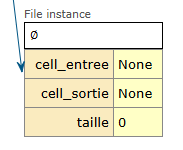
    
On enfile une première valeur :  
    
```python
f.enfile(10)    
```     
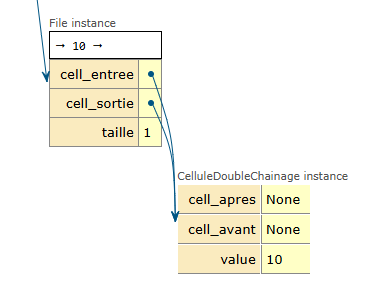
    
On enfile une deuxième valeur :  
    
```python
f.enfile(20)    
```
    
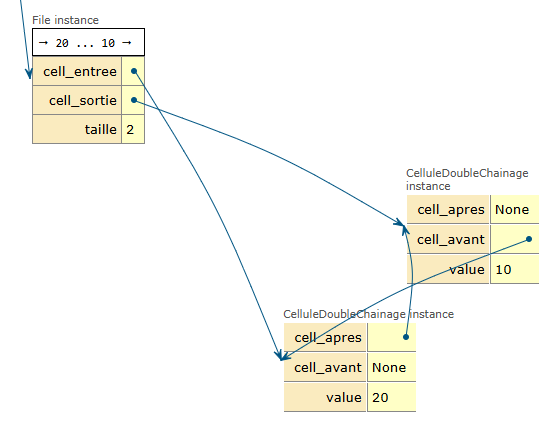
    
On enfile une troisième valeur :  
    
```python
f.enfile(30)    
```    
    
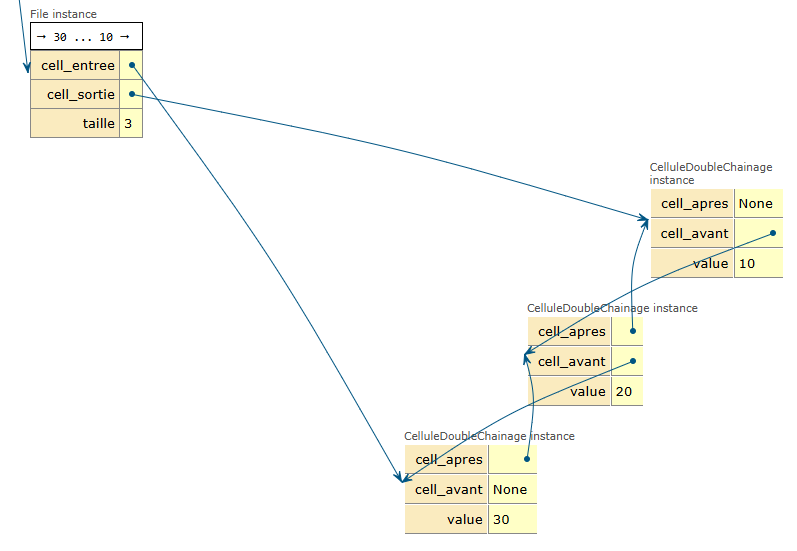    
    
</div>  

In [ ]:
class CelluleDoubleChainage:
    def __init__(self, value):
        self.value = value
        self.cell_avant = None
        self.cell_apres = None
        
    def set_suivant(self, cell):
        if not isinstance(cell, (CelluleDoubleChainage, type(None))):
            raise ValueError('Type cell incorrecte.')  
        self.cell_apres = cell
        
    def set_precedent(self, cell):
        if not isinstance(cell, (CelluleDoubleChainage, type(None))):
            raise ValueError('Type cell incorrecte.')  
        self.cell_avant = cell
        

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer
   
Implémentez cette classe et toutes ses méthodes.  
    
```python
class File:
    def __init__(self):
        self.cell_entree = ...
        self.cell_sortie = ...
        self.taille = ...

    def valeur(self):
        """Renvoie la valeur en sortie de la file.
        """
        if self.est_vide():
            raise ValueError('La file est vide.')
            

    def defile(self):
        """Défile le dernier élément saisi.
        """
        if self.est_vide():
            raise ValueError('La file est vide.')
    
    def enfile(self, v):
        """Emfile la valeur v
        """
        ...
    
    def est_vide(self):
        """Renvoie True si la file est vide, False sinon
        """
        ...
    
    def __len__(self):
        """Renvoie le nombre d'élément dans la file
        """
        ...
   
```    
    
    
Testez-là !
</div>

In [ ]:
class File:
    def __init__(self):
        self.cell_entree = ...
        self.cell_sortie = ...
        self.taille = ...

    def valeur(self):
        """Renvoie la valeur en sortie de la file.
        """
        if self.est_vide():
            raise ValueError('La file est vide.')
            

    def defile(self):
        """Défile le dernier élément saisi.
        """
        if self.est_vide():
            raise ValueError('La file est vide.')
    
    def enfile(self, v):
        """Emfile la valeur v
        """
        ...
    
    def est_vide(self):
        """Renvoie True si la file est vide, False sinon
        """
        ...
    
    def __len__(self):
        """Renvoie le nombre d'élément dans la file
        """
        ...
    
    def __repr__(self):
        """Renvoie une représentation str de toute la file
        """
        if self.est_vide():
            return '⭢ ∅'        
        txt = "⭢ "
        c = self.cell_entree
        while c is not None:
            txt += f"{c.value} "
            c = c.cell_apres
        return txt + "⭢"     
    
    def __str__(self):
        """Renvoie une représentation str de la sortie de la file.
        """        
        if self.est_vide():
            return '⭢ ∅'
        if len(self) == 1:
            return f'⭢ {self.valeur()} ⭢'        
        return f'⭢ {self.cell_entree.value} ... {self.valeur()} ⭢'
            

In [ ]:
f = File()
print(len(f), f.est_vide())
for i in range(10):
    print(f)
    f.enfile(i)
print(f)
print(len(f), f.est_vide())

In [ ]:
while not f.est_vide():
    print(f, f.defile())

<div class = "alert alert-block alert-info">   
    
    
## Traitement récursif des listes chainées
    
Les listes chaînées sont à la base du langage **LISP** (List Processing) datant de 1958, utilisant des listes pour représenter des expressions arithmétiques (appelée S-expressions).  
**LISP** est un langage fonctionnel qui ne permet aucune boucle, ni `while`, ni `for`, qui seront alors traités récursivement.   
   
Le principe de traitement est basé sur :   
    
- Une tête (**head**) représentée par une valeur ;    
- Un reste (appelé queue **tail**) représentant le reste de la structure.      
       
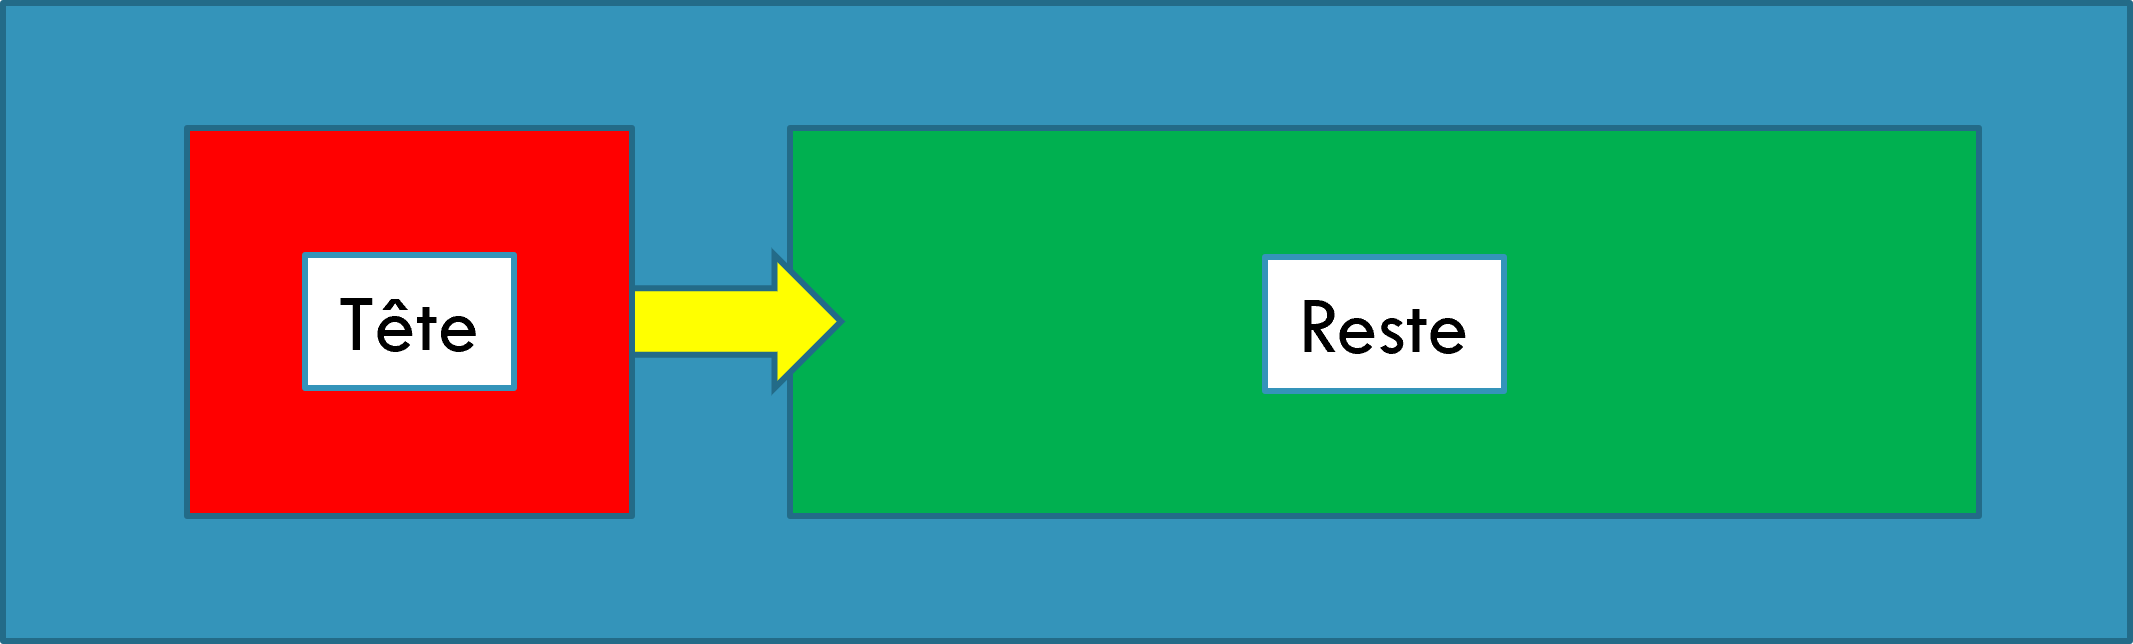
    
Le reste de la structure va également posséder une tête et un reste, qui lui-même possédera une tête et un reste ... Jusqu'à atteindre le bout de la structure, représenté par un reste vide (**`None`** en python).    
    
Ce type de structure est donc particulièrement bien adaptée au traitement récursif :    
    
- On applique un traitement sur la tête ;    
- On relance la fonction sur la queue.  
    
    
## Classe ListeChainee
    
Voici une classe **`ListeChainee`** qui sert à la fois de maillon et de liste chainée. Elle dispose du minimum :   
    
- pas de notion de liste vide autre que **`None`** ;
- une méthode **`head`** renvoie la valeur de la première cellule ;   
- une méthode **`tail`** renvoie le reste, c'est a dire le pointeur vers la cellule suivante.
- la classe est compatible avec l'opérateur **`+`** (grâce à la méthode **`__add__`**) qui permet la concaténation de deux listes en une nouvelle liste ;   
- la structure est itérable grâce aux méthodes **`iter`** et **`next`**.   
    
Dans un langage fonctionnel, les données sont immuables et ne peuvent être modifiées. On ne peut donc pas ajouter, ni retirer une valeur. Une liste est crée en une seule fois, a partir d'une série de données ou d'une liste existante.   
    
Voici cette classe, complète et fonctionnelle :    
    
```python
class ListeChainee:
    def __init__(self, value, *values):
        """
        Classe pour modéliser une cellule de la liste chainée
        2 attributs publics :
            value : valeur de la cellule
            next_cell : pointeur vers la cellule suivante (autre instance de Cellule)
        """
        #attributs publics
        self.value = value
        if values == ():
            self.next_cell = None
        else:
            self.next_cell = ListeChainee(*values)
        
    def head(self):
        """Renvoi la valeur de la première cellule.
        """
        return self.value
    
    def tail(self):
        """Renvoi la fin de la liste.
        
        return
            Liste_c ou None
                La seconde cellule (chainée a toutes les suivantes), 
                None si la liste comporte un seul élément.
        """
        return self.next_cell
    
    def __add__(self, cell):
        """Rend les instances compatibles avec l'opération +.
        
        parametre:
            cell : ListeChainee ou None
            
        return:
            ListeChainee
                Une nouvelle instance, concaténation de self et de cell. Une copie est crée.
        """
        new = ListeChainee(self.value)
        c_new = new
        for c in (self.next_cell, cell):
            while c is not None:
                c_new.next_cell = ListeChainee(c.value)
                c = c.next_cell
                c_new = c_new.next_cell
        return new

    def __repr__(self):
        """renvoi une représentation str de la liste.
        
        return: str
            Exemple : '〘1, 2, 3, 4, 5〙'
        """
        txt = f'〘{self.value}'
        c = self.next_cell
        while c is not None:
            txt += f', {c.value}'
            c = c.next_cell
        txt += '〙'
        return txt
    
    def __iter__(self):
        """Renvoi un itérateur"""
        self.cell_iter = self
        return self
    
    def __next__(self):
        """renvoi la valeur suivante de la liste. Une exception est levée si il n'y a plus rien a envoyer.
        """
        if self.cell_iter is None:
            raise StopIteration        
        v = self.cell_iter.value
        self.cell_iter = self.cell_iter.next_cell
        return v
```    
    
</div>    

In [ ]:
class ListeChainee:
    def __init__(self, value, *values):
        """
        Classe pour modéliser une cellule de la liste chainée
        2 attributs publics :
            value : valeur de la cellule
            next_cell : pointeur vers la cellule suivante (autre instance de Cellule)
        """
        #attributs publics
        self.value = value
        if values == ():
            self.next_cell = None
        else:
            self.next_cell = ListeChainee(*values)
        
    def head(self):
        """Renvoi la valeur de la première cellule.
        """
        return self.value
    
    def tail(self):
        """Renvoi la fin de la liste.
        
        return
            Liste_c ou None
                La seconde cellule (chainée a toutes les suivantes), 
                None si la liste comporte un seul élément.
        """
        return self.next_cell
    
    def __add__(self, cell):
        """Rend les instances compatibles avec l'opération +.
        
        parametre:
            cell : ListeChainee ou None
            
        return:
            ListeChainee
                Une nouvelle instance, concaténation de self et de cell. Une copie est crée.
        """
        new = ListeChainee(self.value)
        c_new = new
        for c in (self.next_cell, cell):
            while c is not None:
                c_new.next_cell = ListeChainee(c.value)
                c = c.next_cell
                c_new = c_new.next_cell
        return new

    def __repr__(self):
        """renvoi une représentation str de la liste.
        
        return: str
            Exemple : '〘1, 2, 3, 4, 5〙'
        """
        txt = f'〘{self.value}'
        c = self.next_cell
        while c is not None:
            txt += f', {c.value}'
            c = c.next_cell
        txt += '〙'
        return txt
    
    def __iter__(self):
        """Renvoi un itérateur"""
        self.cell_iter = self
        return self
    
    def __next__(self):
        """renvoi la valeur suivante de la liste. Une exception est levée si il n'y a plus rien a envoyer.
        """
        if self.cell_iter is None:
            raise StopIteration        
        v = self.cell_iter.value
        self.cell_iter = self.cell_iter.next_cell
        return v

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer

Testez cette classe ci-dessous, en utilisant toutes ses méthodes. 
</div>

In [ ]:
# Création et addition de deux listes
...

In [ ]:
# itération
...

In [ ]:
# head et tail
...

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer

Ecrivez une fonction **`double(lst)`** qui renvoie une liste chainée dont les éléments sont le double des éléments de **`lst`**.
    
```python
>>> l1 = ListeChainee(12, 13, 14, 15, 16)
>>> l2 = double(l1)
>>> l2
〘24, 26, 28, 30, 32〙    
```    
    
</div>

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer

Ecrivez une fonction **`applique(fct, lst)`** qui applique la fonction **`fct`** à tout les éléments de **`lst`** et renvoie une nouvelle liste chainée contenant les résultats.
    
```python
>>> l1 = ListeChainee(1, 2, 3, 4)
>>> l2 = applique(lambda x: x + 1, l1)
>>> l2
〘2, 3, 4, 5〙 
```    
    
    
</div>

<div class = "alert alert-block alert-warning"> 
    
### A vous de jouer

Ecrivez une fonction **`somme(lst)`** qui renvoie la somme des éléments de la liste **`lst`**.
    
```python
>>> l1 = ListeChainee(1, 2, 3, 4)
>>> somme(l1)
10 
```    
    
    
</div>